In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import ast
import scipy
import mdtraj as md
from typing import Dict, Tuple
import os
import math

# matplotlib settings
# --- Publication style settings ---
plt.rcParams.update({
    # Font
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "text.usetex": False,

    # Editable, Affinity-compatible font embedding
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",

    # Figure
    "figure.figsize": (6, 4),
    "figure.dpi": 150,

    # Axes
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.linewidth": 1.2,
    "axes.grid": True,
    "grid.linestyle": "--",
    "grid.alpha": 0.7,

    # Ticks
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    # Lines
    "lines.linewidth": 2,
    "lines.markersize": 6,

    # Legend
    "legend.fontsize": 10,
    "legend.frameon": False
})

def calc_ccc(x, y):
    x = np.asarray(x)
    y = np.asarray(y)

    mx = np.mean(x)
    my = np.mean(y)
    vx = np.var(x, ddof=0)
    vy = np.var(y, ddof=0)
    sxy = np.cov(x, y, ddof=0)[0, 1]

    return 2 * sxy / (vx + vy + (mx - my) ** 2)

import scipy.stats

# functions to calculate statistics
def RMSE(actual, predicted):
    
    # Convert inputs to numpy arrays 
    actual = np.array(actual)
    predicted = np.array(predicted)
    
    # Calculate the squared differences
    squared_diff = (actual - predicted) ** 2
    
    # Compute the mean of squared differences
    mean_squared_diff = np.mean(squared_diff)
    
    # Take the square root of the mean squared difference
    return np.sqrt(mean_squared_diff)


outpath='./'

model_params = {'BV2006': {'beta_c': 0.35, 'beta_h': 2.00}, 'BV2006ang': {'beta_c': 0.89, 'beta_h': 4.39}}


Total unique proteins: 8


/tmp/ipykernel_1941938/3373077557.py:47: DeprecationWarning: loadtxt(): Parsing an integer via a float is deprecated.  To avoid this warning, you can:
    * make sure the original data is stored as integers.
    * use the `converters=` keyword argument.  If you only use
      NumPy 1.23 or later, `converters=float` will normally work.
    * Use `np.loadtxt(...).astype(np.int64)` parsing the file as
      floating point and then convert it.  (On all NumPy versions.)
  (Deprecated NumPy 1.23)
  amide_residues = np.loadtxt(f"../../MD_DATA/{protein}/rew{model}/amideresidues.txt", dtype=int)


/tmp/ipykernel_1941938/3373077557.py:47: DeprecationWarning: loadtxt(): Parsing an integer via a float is deprecated.  To avoid this warning, you can:
    * make sure the original data is stored as integers.
    * use the `converters=` keyword argument.  If you only use
      NumPy 1.23 or later, `converters=float` will normally work.
    * Use `np.loadtxt(...).astype(np.int64)` parsing the file as
      floating point and then convert it.  (On all NumPy versions.)
  (Deprecated NumPy 1.23)
  amide_residues = np.loadtxt(f"../../MD_DATA/{protein}/rew{model}/amideresidues.txt", dtype=int)
/tmp/ipykernel_1941938/3373077557.py:47: DeprecationWarning: loadtxt(): Parsing an integer via a float is deprecated.  To avoid this warning, you can:
    * make sure the original data is stored as integers.
    * use the `converters=` keyword argument.  If you only use
      NumPy 1.23 or later, `converters=float` will normally work.
    * Use `np.loadtxt(...).astype(np.int64)` parsing the file as
    

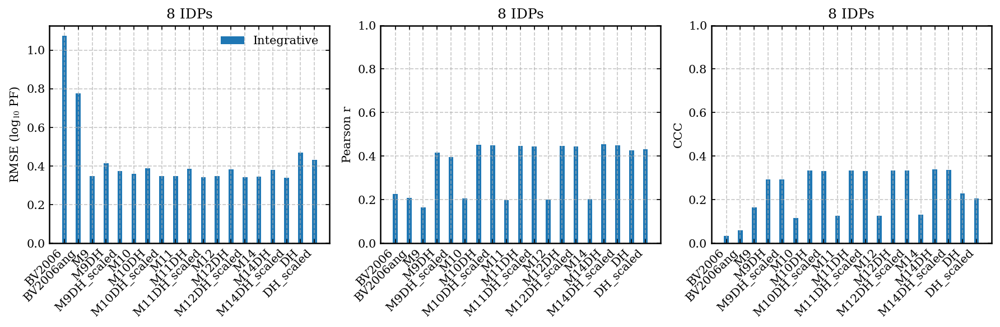

IOStream.flush timed out


In [2]:
# only integrative IDPs

models = ['BV2006', 'BV2006ang', 'M9', 'M9DH', 'M9DH_scaled','M10', 'M10DH', 'M10DH_scaled', 
'M11', 'M11DH', 'M11DH_scaled',  'M12', 'M12DH', 'M12DH_scaled', 
'M14', 'M14DH', 'M14DH_scaled', 'DH', 'DH_scaled'] 

proteins = ['AAQAA3', 'ACTR', 'aSyn', 'BecN', 'drkN', 'ChiZ', 'd131d', 'NTail']

print("Total unique proteins:", len(proteins))

# ---- storage for means ----
rmse_mean  = []
r_mean   = []
ccc_mean     = []
all_exp_PF = []
all_sim_PF = []

# ---- loop through models ----
for model in models:

    rmse_vals = []
    r_vals  = []
    ccc_vals     = []
    exp_PF_vals = []
    sim_PF_vals = []
    residues_vals = []
    protein_vals = []


    for protein in proteins:
        
        # load experimental data
        exp_data = pd.read_csv(f"../../EXP_DATA/PF_Nguyen_2018/{protein}.csv")
        exp_res = exp_data['Model_residue'].values
        PF_exp = exp_data['PF'].values
        logPF_exp = np.log10(PF_exp)

        # load integrative weights
        weights = np.load(f'../{protein}/final_wopt.npy')

        # load simulated data
        if 'BV' in model:
            sim_data1 = np.load(f"../../MD_DATA/{protein}/rew{model}/contacts_res_frames.npy")
            sim_data2 = np.load(f"../../MD_DATA/{protein}/rew{model}/hbonds_res_frames.npy")
            sim_data = model_params[model]['beta_c']*sim_data1 + model_params[model]['beta_h']*sim_data2
            PF_sim = np.exp(np.average(sim_data, axis=0, weights=weights))
            amide_residues = np.loadtxt(f"../../MD_DATA/{protein}/rew{model}/amideresidues.txt", dtype=int)
        else:
            for fname in ["fopen.npy", "fopenDH.npy", "O.npy"]:
                path = f"../../MD_DATA/{protein}/rew{model}/{fname}"
                try:
                    fopen = np.load(path)
                    break
                except FileNotFoundError:
                    continue
            amide_residues = np.loadtxt(f"../../MD_DATA/{protein}/rewM10/amideresidues.txt", dtype=int)
            
            PF_sim = 1/np.average(fopen, axis=0, weights=weights)

        # align simulated and experimental data
        exp_idxs = []
        for res in exp_res:
            if res in amide_residues:
                exp_idxs.append(np.where(amide_residues == res)[0][0])
        exp_idxs = np.array(exp_idxs)
        PF_sim = PF_sim[exp_idxs]
        logPF_sim = np.log10(PF_sim)

        # stats: RMSE, Pearson r, CCC
        rmse_vals.append(RMSE(logPF_exp, logPF_sim))
        r_vals.append(scipy.stats.pearsonr(logPF_exp, logPF_sim)[0])
        ccc_vals.append(calc_ccc(logPF_exp, logPF_sim))
        exp_PF_vals.extend(PF_exp)
        sim_PF_vals.extend(PF_sim)
        residues_vals.extend(exp_res)
        protein_vals.extend(np.repeat(protein, len(exp_res)))

    # save df for this model
    df = pd.DataFrame({
        'Protein': protein_vals,
        'Residue': residues_vals,
        'PF_Exp': exp_PF_vals,
        'PF_Sim': sim_PF_vals
    })
    df.to_csv(f"{model}_PF_perres_comparison.csv", index=False)

    # store means
    rmse_mean.append(np.mean(rmse_vals))
    r_mean.append(np.mean(r_vals))
    ccc_mean.append(np.mean(ccc_vals))
    all_exp_PF.append(exp_PF_vals)
    all_sim_PF.append(sim_PF_vals)

# ---- Plot: Two Panels (RMSE and Pearson r) ----

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
bar_width = 0.35
x = np.arange(len(models))

# ===== LEFT PANEL: RMSE =====
ax = axes[0]

ax.bar(x , rmse_mean, bar_width, label="Integrative", color="tab:blue")
ax.set_title(f"{len(proteins)} IDPs")
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=45, ha='right')
ax.set_ylabel("RMSE (log$_{10}$ PF)")
ax.legend()

# ===== MIDDLE PANEL: Pearson r =====
ax = axes[1]

ax.bar(x , r_mean, bar_width, label="Integrative", color="tab:blue")
ax.set_title(f"{len(proteins)} IDPs")
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=45, ha='right')
ax.set_ylabel("Pearson r")
ax.set_ylim(0,1)

# ===== RIGHT PANEL: CCC =====
ax = axes[2]

ax.bar(x , ccc_mean, bar_width, label="Integrative", color="tab:blue")
ax.set_title(f"{len(proteins)} IDPs")
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=45, ha='right')
ax.set_ylabel("CCC")
ax.set_ylim(0,1)

plt.tight_layout()
plt.savefig(f"models_HDXstats_summary.png", dpi=200, bbox_inches="tight")



Total unique proteins: 8


/tmp/ipykernel_1941938/1691441676.py:42: DeprecationWarning: loadtxt(): Parsing an integer via a float is deprecated.  To avoid this warning, you can:
    * make sure the original data is stored as integers.
    * use the `converters=` keyword argument.  If you only use
      NumPy 1.23 or later, `converters=float` will normally work.
    * Use `np.loadtxt(...).astype(np.int64)` parsing the file as
      floating point and then convert it.  (On all NumPy versions.)
  (Deprecated NumPy 1.23)
  amide_residues = np.loadtxt(f"../../MD_DATA/{protein}/rew{model}/amideresidues.txt", dtype=int)
/tmp/ipykernel_1941938/1691441676.py:42: DeprecationWarning: loadtxt(): Parsing an integer via a float is deprecated.  To avoid this warning, you can:
    * make sure the original data is stored as integers.
    * use the `converters=` keyword argument.  If you only use
      NumPy 1.23 or later, `converters=float` will normally work.
    * Use `np.loadtxt(...).astype(np.int64)` parsing the file as
    

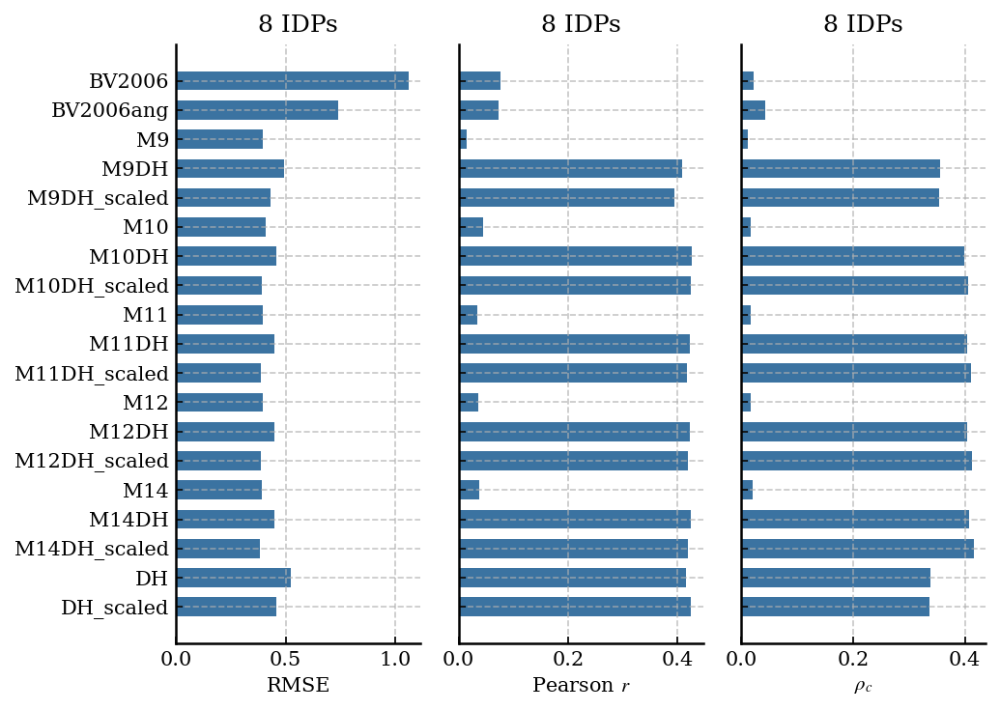

In [7]:

# only integrative IDPs

models = ['BV2006', 'BV2006ang', 'M9', 'M9DH', 'M9DH_scaled', 'M10', 'M10DH', 'M10DH_scaled',
          'M11', 'M11DH', 'M11DH_scaled', 'M12', 'M12DH', 'M12DH_scaled',
          'M14', 'M14DH', 'M14DH_scaled', 'DH', 'DH_scaled']

proteins = ['AAQAA3', 'ACTR', 'aSyn', 'BecN', 'drkN', 'ChiZ', 'd131d', 'NTail']

print("Total unique proteins:", len(proteins))

COLOR = "#3B73A1"

rmse_all = []
r_all = []
ccc_all = []
all_exp_PF = []
all_sim_PF = []

for model in models:

    exp_PF_vals = []
    sim_PF_vals = []
    residues_vals = []
    protein_vals = []

    for protein in proteins:

        # load experimental data
        exp_data = pd.read_csv(f"../../EXP_DATA/PF_Nguyen_2018/{protein}.csv")
        exp_res = exp_data['Model_residue'].values
        PF_exp = exp_data['PF'].values

        # load integrative weights
        weights = np.load(f"../{protein}/final_wopt.npy")

        # load simulated data
        if 'BV' in model:
            sim_data1 = np.load(f"../../MD_DATA/{protein}/rew{model}/contacts_res_frames.npy")
            sim_data2 = np.load(f"../../MD_DATA/{protein}/rew{model}/hbonds_res_frames.npy")
            sim_data = model_params[model]['beta_c'] * sim_data1 + model_params[model]['beta_h'] * sim_data2
            PF_sim = np.exp(np.average(sim_data, axis=0, weights=weights))
            amide_residues = np.loadtxt(f"../../MD_DATA/{protein}/rew{model}/amideresidues.txt", dtype=int)
        else:
            fopen = None
            for fname in ["fopen.npy", "fopenDH.npy", "O.npy"]:
                path = f"../../MD_DATA/{protein}/rew{model}/{fname}"
                try:
                    fopen = np.load(path)
                    break
                except FileNotFoundError:
                    continue

            if fopen is None:
                raise FileNotFoundError(f"No fopen.npy, fopenDH.npy or O.npy found for {protein}, {model}")

            amide_residues = np.loadtxt(f"../../MD_DATA/{protein}/rewM10/amideresidues.txt", dtype=int)
            PF_sim = 1 / np.average(fopen, axis=0, weights=weights)

        # align simulated and experimental data
        matched_exp_idxs = []
        matched_sim_idxs = []

        for exp_idx, res in enumerate(exp_res):
            if res in amide_residues:
                matched_exp_idxs.append(exp_idx)
                matched_sim_idxs.append(np.where(amide_residues == res)[0][0])

        matched_exp_idxs = np.asarray(matched_exp_idxs, dtype=int)
        matched_sim_idxs = np.asarray(matched_sim_idxs, dtype=int)

        PF_exp_matched = PF_exp[matched_exp_idxs]
        PF_sim_matched = PF_sim[matched_sim_idxs]
        exp_res_matched = exp_res[matched_exp_idxs]

        valid = np.isfinite(PF_exp_matched) & np.isfinite(PF_sim_matched) & (PF_exp_matched > 0) & (PF_sim_matched > 0)

        PF_exp_matched = PF_exp_matched[valid]
        PF_sim_matched = PF_sim_matched[valid]
        exp_res_matched = exp_res_matched[valid]

        exp_PF_vals.extend(PF_exp_matched)
        sim_PF_vals.extend(PF_sim_matched)
        residues_vals.extend(exp_res_matched)
        protein_vals.extend(np.repeat(protein, len(PF_exp_matched)))

    exp_PF_vals = np.asarray(exp_PF_vals)
    sim_PF_vals = np.asarray(sim_PF_vals)

    log_exp = np.log10(exp_PF_vals)
    log_sim = np.log10(sim_PF_vals)

    # calculate statistics using all pooled residues
    rmse_all.append(RMSE(log_exp, log_sim))
    r_all.append(scipy.stats.pearsonr(log_exp, log_sim)[0])
    ccc_all.append(calc_ccc(log_exp, log_sim))

    all_exp_PF.append(exp_PF_vals)
    all_sim_PF.append(sim_PF_vals)

    # save dataframe for this model
    df = pd.DataFrame({'Protein': protein_vals, 'Residue': residues_vals, 'PF_Exp': exp_PF_vals, 'PF_Sim': sim_PF_vals})
    df.to_csv(f"{model}_PF_perres_comparison.csv", index=False)

# ---- Plot ----
fig, axes = plt.subplots(1, 3, figsize=(7, 5), sharey=True)

y = np.arange(len(models))

for ax, values, xlabel in zip(axes, [rmse_all, r_all, ccc_all], ['RMSE', 'Pearson $r$', r'$\mathit{\rho_c}$']):
    ax.barh(y, values, height=0.65, color=COLOR)
    ax.set_xlabel(xlabel)
    ax.axvline(0, color='black', linewidth=0.8)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(axis='both', which='both', top=False, right=False)

axes[0].set_yticks(y)
axes[0].set_yticklabels(models)
axes[0].invert_yaxis()

axes[0].set_title(f"{len(proteins)} IDPs")
axes[1].set_title(f"{len(proteins)} IDPs")
axes[2].set_title(f"{len(proteins)} IDPs")

plt.tight_layout()
plt.savefig('models_HDXstats_summary.pdf', dpi=300)
plt.show()



Total unique proteins: 8


/tmp/ipykernel_1941938/2878835595.py:42: DeprecationWarning: loadtxt(): Parsing an integer via a float is deprecated.  To avoid this warning, you can:
    * make sure the original data is stored as integers.
    * use the `converters=` keyword argument.  If you only use
      NumPy 1.23 or later, `converters=float` will normally work.
    * Use `np.loadtxt(...).astype(np.int64)` parsing the file as
      floating point and then convert it.  (On all NumPy versions.)
  (Deprecated NumPy 1.23)
  amide_residues = np.loadtxt(f"../../MD_DATA/{protein}/rew{model}/amideresidues.txt", dtype=int)
/tmp/ipykernel_1941938/2878835595.py:42: DeprecationWarning: loadtxt(): Parsing an integer via a float is deprecated.  To avoid this warning, you can:
    * make sure the original data is stored as integers.
    * use the `converters=` keyword argument.  If you only use
      NumPy 1.23 or later, `converters=float` will normally work.
    * Use `np.loadtxt(...).astype(np.int64)` parsing the file as
    

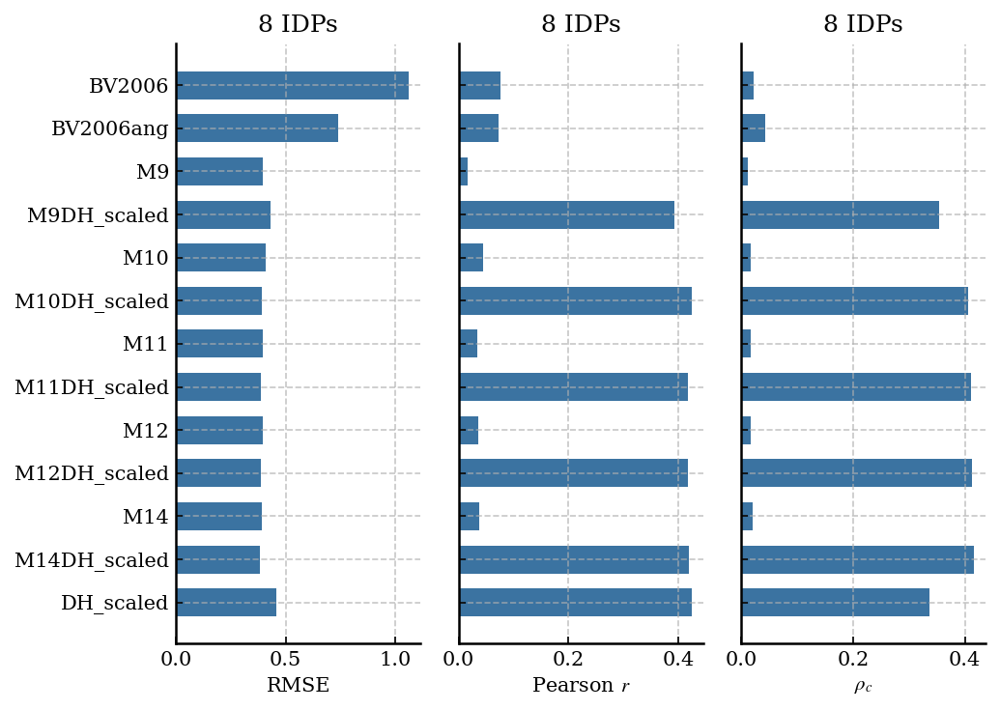

In [8]:

# only integrative IDPs

models = ['BV2006', 'BV2006ang', 'M9', 'M9DH_scaled', 'M10', 'M10DH_scaled',
          'M11', 'M11DH_scaled', 'M12', 'M12DH_scaled',
          'M14', 'M14DH_scaled', 'DH_scaled']

proteins = ['AAQAA3', 'ACTR', 'aSyn', 'BecN', 'drkN', 'ChiZ', 'd131d', 'NTail']

print("Total unique proteins:", len(proteins))

COLOR = "#3B73A1"

rmse_all = []
r_all = []
ccc_all = []
all_exp_PF = []
all_sim_PF = []

for model in models:

    exp_PF_vals = []
    sim_PF_vals = []
    residues_vals = []
    protein_vals = []

    for protein in proteins:

        # load experimental data
        exp_data = pd.read_csv(f"../../EXP_DATA/PF_Nguyen_2018/{protein}.csv")
        exp_res = exp_data['Model_residue'].values
        PF_exp = exp_data['PF'].values

        # load integrative weights
        weights = np.load(f"../{protein}/final_wopt.npy")

        # load simulated data
        if 'BV' in model:
            sim_data1 = np.load(f"../../MD_DATA/{protein}/rew{model}/contacts_res_frames.npy")
            sim_data2 = np.load(f"../../MD_DATA/{protein}/rew{model}/hbonds_res_frames.npy")
            sim_data = model_params[model]['beta_c'] * sim_data1 + model_params[model]['beta_h'] * sim_data2
            PF_sim = np.exp(np.average(sim_data, axis=0, weights=weights))
            amide_residues = np.loadtxt(f"../../MD_DATA/{protein}/rew{model}/amideresidues.txt", dtype=int)
        else:
            fopen = None
            for fname in ["fopen.npy", "fopenDH.npy", "O.npy"]:
                path = f"../../MD_DATA/{protein}/rew{model}/{fname}"
                try:
                    fopen = np.load(path)
                    break
                except FileNotFoundError:
                    continue

            if fopen is None:
                raise FileNotFoundError(f"No fopen.npy, fopenDH.npy or O.npy found for {protein}, {model}")

            amide_residues = np.loadtxt(f"../../MD_DATA/{protein}/rewM10/amideresidues.txt", dtype=int)
            PF_sim = 1 / np.average(fopen, axis=0, weights=weights)

        # align simulated and experimental data
        matched_exp_idxs = []
        matched_sim_idxs = []

        for exp_idx, res in enumerate(exp_res):
            if res in amide_residues:
                matched_exp_idxs.append(exp_idx)
                matched_sim_idxs.append(np.where(amide_residues == res)[0][0])

        matched_exp_idxs = np.asarray(matched_exp_idxs, dtype=int)
        matched_sim_idxs = np.asarray(matched_sim_idxs, dtype=int)

        PF_exp_matched = PF_exp[matched_exp_idxs]
        PF_sim_matched = PF_sim[matched_sim_idxs]
        exp_res_matched = exp_res[matched_exp_idxs]

        valid = np.isfinite(PF_exp_matched) & np.isfinite(PF_sim_matched) & (PF_exp_matched > 0) & (PF_sim_matched > 0)

        PF_exp_matched = PF_exp_matched[valid]
        PF_sim_matched = PF_sim_matched[valid]
        exp_res_matched = exp_res_matched[valid]

        exp_PF_vals.extend(PF_exp_matched)
        sim_PF_vals.extend(PF_sim_matched)
        residues_vals.extend(exp_res_matched)
        protein_vals.extend(np.repeat(protein, len(PF_exp_matched)))

    exp_PF_vals = np.asarray(exp_PF_vals)
    sim_PF_vals = np.asarray(sim_PF_vals)

    log_exp = np.log10(exp_PF_vals)
    log_sim = np.log10(sim_PF_vals)

    # calculate statistics using all pooled residues
    rmse_all.append(RMSE(log_exp, log_sim))
    r_all.append(scipy.stats.pearsonr(log_exp, log_sim)[0])
    ccc_all.append(calc_ccc(log_exp, log_sim))

    all_exp_PF.append(exp_PF_vals)
    all_sim_PF.append(sim_PF_vals)

    # save dataframe for this model
    df = pd.DataFrame({'Protein': protein_vals, 'Residue': residues_vals, 'PF_Exp': exp_PF_vals, 'PF_Sim': sim_PF_vals})
    #df.to_csv(f"{model}_PF_perres_comparison.csv", index=False) # to not overwrite

# ---- Plot ----
fig, axes = plt.subplots(1, 3, figsize=(7, 5), sharey=True)

y = np.arange(len(models))

for ax, values, xlabel in zip(axes, [rmse_all, r_all, ccc_all], ['RMSE', 'Pearson $r$', r'$\mathit{\rho_c}$']):
    ax.barh(y, values, height=0.65, color=COLOR)
    ax.set_xlabel(xlabel)
    ax.axvline(0, color='black', linewidth=0.8)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(axis='both', which='both', top=False, right=False)

axes[0].set_yticks(y)
axes[0].set_yticklabels(models)
axes[0].invert_yaxis()

axes[0].set_title(f"{len(proteins)} IDPs")
axes[1].set_title(f"{len(proteins)} IDPs")
axes[2].set_title(f"{len(proteins)} IDPs")

plt.tight_layout()
plt.savefig('models_HDXstats_summary_maintext_fig.pdf', dpi=300)
plt.show()



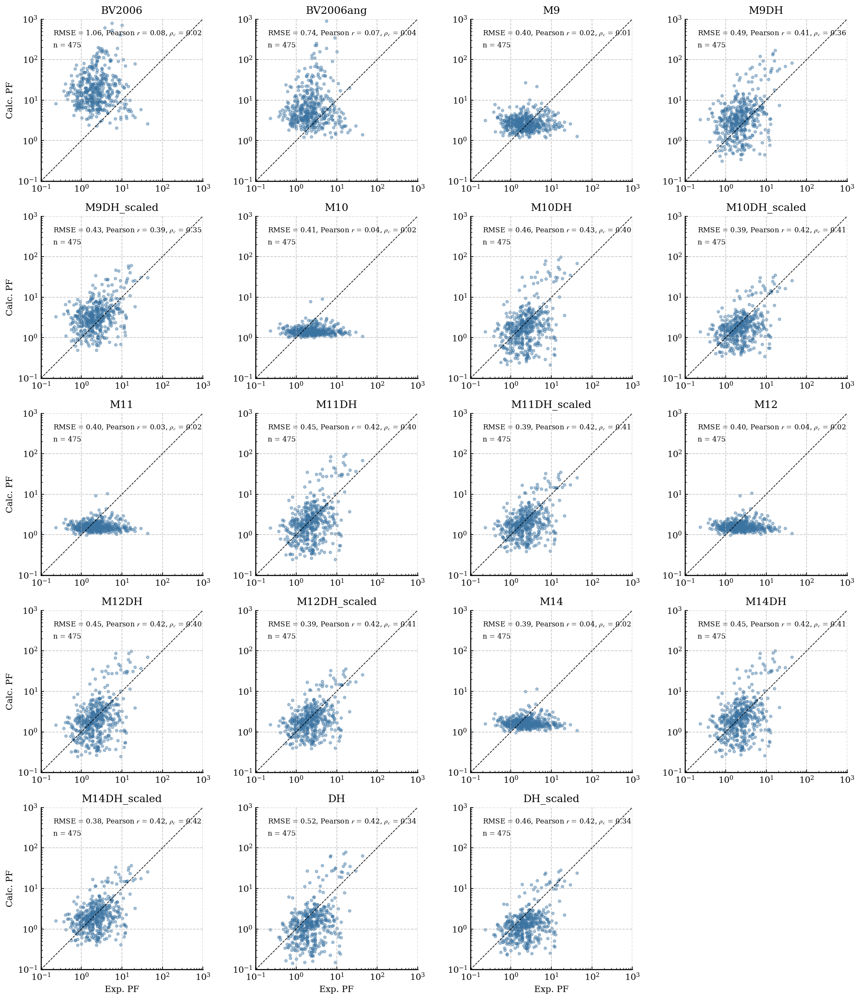

In [14]:

models = ['BV2006', 'BV2006ang', 'M9', 'M9DH', 'M9DH_scaled', 'M10', 'M10DH', 'M10DH_scaled',
          'M11', 'M11DH', 'M11DH_scaled', 'M12', 'M12DH', 'M12DH_scaled',
          'M14', 'M14DH', 'M14DH_scaled', 'DH', 'DH_scaled']

xmin, xmax = 1e-1, 1e3
ymin, ymax = 1e-1, 1e3

n_models = len(models)
ncols = 4
nrows = math.ceil(n_models / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(14, 3.2 * nrows))
axes = np.asarray(axes).flatten()

for i, (ax, model) in enumerate(zip(axes, models)):

    df = pd.read_csv(f"{model}_PF_perres_comparison.csv")
    
    exp_pf = np.asarray(df['PF_Exp'])
    sim_pf = np.asarray(df['PF_Sim'])

    log_exp = np.log10(exp_pf)
    log_sim = np.log10(sim_pf)

    rmse_val = RMSE(log_exp, log_sim)
    r_val = scipy.stats.pearsonr(log_exp, log_sim)[0]
    ccc_val = calc_ccc(log_exp, log_sim)

    n = len(exp_pf)

    ax.scatter(exp_pf, sim_pf, color='#3B73A1', alpha=0.4, s=9, rasterized=True)

    x = np.linspace(xmin, xmax, 200)
    ax.plot(x, x, color='black', linestyle='dashed', linewidth=0.75)

    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_aspect('equal', adjustable='box')

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(axis='both', which='both', top=False, right=False)

    row = i // ncols
    col = i % ncols

    if row == nrows - 1:
        ax.set_xlabel("Exp. PF")
    if col == 0:
        ax.set_ylabel("Calc. PF")

    ax.set_title(model)

    ax.text(2e-1, 4e2, rf"RMSE = {rmse_val:.2f}, Pearson $r$ = {r_val:.2f}, $\rho_c$ = {ccc_val:.2f}", fontsize=8)
    ax.text(2e-1, 2e2, f"n = {int(n)}", fontsize=8)

for j in range(n_models, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.savefig('HDX_models_exp_vs_calc_PF.pdf', dpi=300)
plt.show()



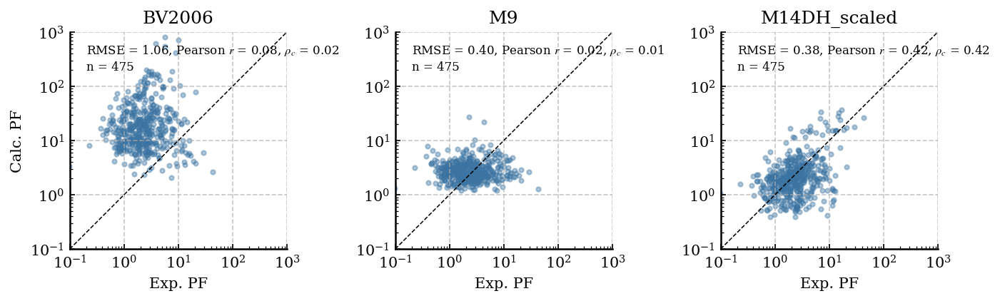

In [15]:

models = ['BV2006', 'M9',  'M14DH_scaled']

xmin, xmax = 1e-1, 1e3
ymin, ymax = 1e-1, 1e3

n_models = len(models)
ncols = 4
nrows = math.ceil(n_models / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(12, 3.2 ))
axes = np.asarray(axes).flatten()

for i, (ax, model) in enumerate(zip(axes, models)):

    df = pd.read_csv(f"{model}_PF_perres_comparison.csv")
        
    exp_pf = np.asarray(df['PF_Exp'])
    sim_pf = np.asarray(df['PF_Sim'])

    log_exp = np.log10(exp_pf)
    log_sim = np.log10(sim_pf)

    rmse_val = RMSE(log_exp, log_sim)
    r_val = scipy.stats.pearsonr(log_exp, log_sim)[0]
    ccc_val = calc_ccc(log_exp, log_sim)

    n = len(exp_pf)

    ax.scatter(exp_pf, sim_pf, color='#3B73A1', alpha=0.4, s=9, rasterized=True)

    x = np.linspace(xmin, xmax, 200)
    ax.plot(x, x, color='black', linestyle='dashed', linewidth=0.75)

    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_aspect('equal', adjustable='box')

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(axis='both', which='both', top=False, right=False)

    row = i // ncols
    col = i % ncols

    if row == nrows - 1:
        ax.set_xlabel("Exp. PF")
    if col == 0:
        ax.set_ylabel("Calc. PF")

    ax.set_title(model)

    ax.text(2e-1, 4e2, rf"RMSE = {rmse_val:.2f}, Pearson $r$ = {r_val:.2f}, $\rho_c$ = {ccc_val:.2f}", fontsize=8)
    ax.text(2e-1, 2e2, f"n = {int(n)}", fontsize=8)

for j in range(n_models, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.savefig('HDX_models_exp_vs_calc_PF_maintext.pdf', dpi=300)
plt.show()



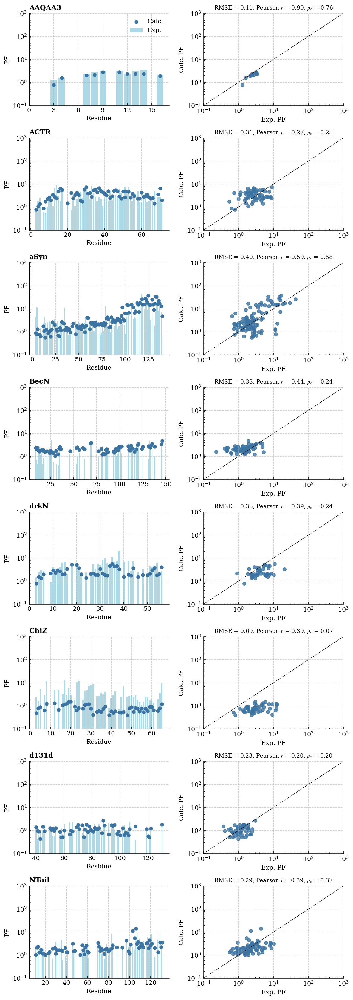

In [23]:
# per-protein plots for one selected model

model = 'M14DH_scaled'

COLOR3 = "#3B73A1"  # deep muted blue
COLOR_EXP = "lightblue"  

nrows = len(proteins)

df_model = pd.read_csv(f"{model}_PF_perres_comparison.csv")

fig, axes = plt.subplots(nrows, 2, figsize=(8, 2.8 * nrows), squeeze=False)

for i, protein in enumerate(proteins):

    ax_pf = axes[i, 0]
    ax_corr = axes[i, 1]

    dfp = df_model[df_model["Protein"] == protein].copy()

    exp_res = dfp["Residue"].values
    PF_exp = dfp["PF_Exp"].values
    PF_sim = dfp["PF_Sim"].values

    logPF_exp = np.log10(PF_exp)
    logPF_sim = np.log10(PF_sim)

    rmse_val = RMSE(logPF_exp, logPF_sim)
    r_val = scipy.stats.pearsonr(logPF_exp, logPF_sim)[0]
    ccc_val = calc_ccc(logPF_exp, logPF_sim)

    # -------------------------
    # left column: residue vs PF
    # -------------------------
    ax_pf.bar(exp_res, PF_exp, width=0.8, color=COLOR_EXP, edgecolor="none", label="Exp.")
    ax_pf.scatter(exp_res, PF_sim, s=25, color=COLOR3, zorder=3, label="Calc.", rasterized=True)

    ax_pf.set_yscale("log")
    ax_pf.set_ylim(1e-1, 1e3)
    ax_pf.set_ylabel("PF")
    ax_pf.set_title(protein, loc="left", fontsize=11, fontweight="bold")

    ax_pf.spines["top"].set_visible(False)
    ax_pf.spines["right"].set_visible(False)
    ax_pf.tick_params(axis="both", which="both", top=False, right=False)
    if protein == 'AAQAA3':
        ax_pf.set_xticks([0, 3, 6, 9, 12, 15])
        ax_pf.set_xticklabels(['0', '3', '6', '9', '12', '15'])

    
    ax_pf.set_xlabel("Residue")

    if i == 0:
        ax_pf.legend(frameon=False)

    # -------------------------
    # right column: correlation plot
    # -------------------------
    ax_corr.scatter(PF_exp, PF_sim, s=28, color=COLOR3, alpha=0.8, rasterized=True)
    ax_corr.plot([1e-1, 1e3], [1e-1, 1e3], color="black", linestyle="dashed", linewidth=0.75)

    ax_corr.set_xscale("log")
    ax_corr.set_yscale("log")
    ax_corr.set_xlim(1e-1, 1e3)
    ax_corr.set_ylim(1e-1, 1e3)

    ax_corr.set_xlabel("Exp. PF")
    ax_corr.set_ylabel("Calc. PF")
    ax_corr.set_title(rf"RMSE = {rmse_val:.2f}, Pearson $r$ = {r_val:.2f}, $\rho_c$ = {ccc_val:.2f}", fontsize=9)

    ax_corr.spines["top"].set_visible(False)
    ax_corr.spines["right"].set_visible(False)
    ax_corr.tick_params(axis="both", which="both", top=False, right=False)



plt.tight_layout()
plt.savefig(f"{model}_PF_perprotein_panels.pdf", dpi=300, bbox_inches="tight")
plt.show()

findfont: Font family ['Times New Roman'] not found. Falling back to DejaVu Sans.
findfont: Font family ['Times New Roman'] not found. Falling back to DejaVu Sans.


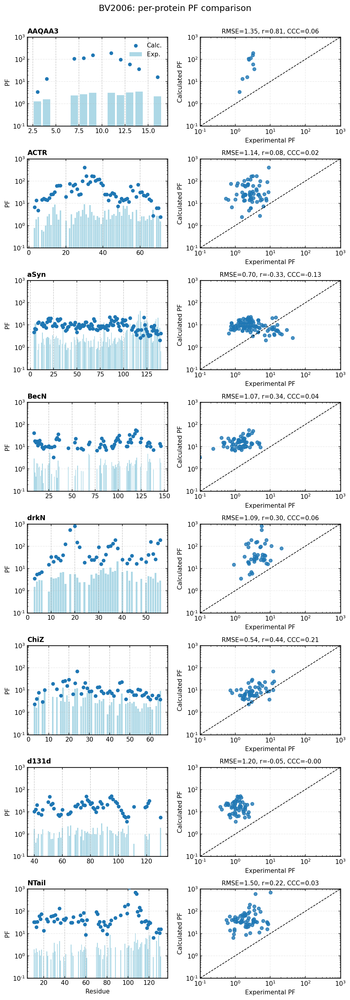

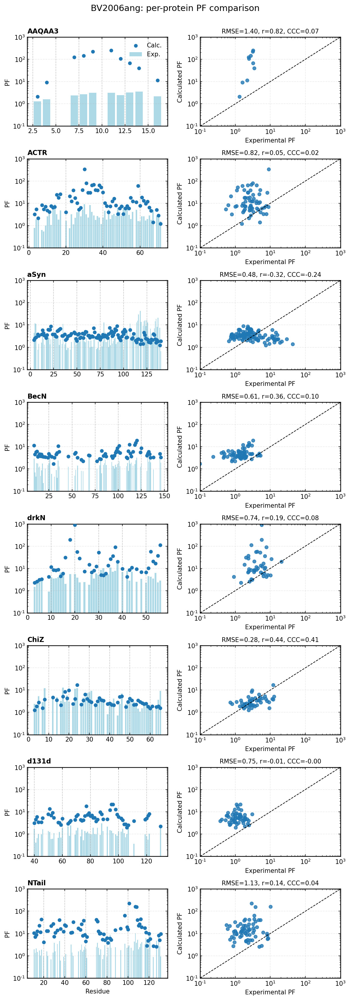

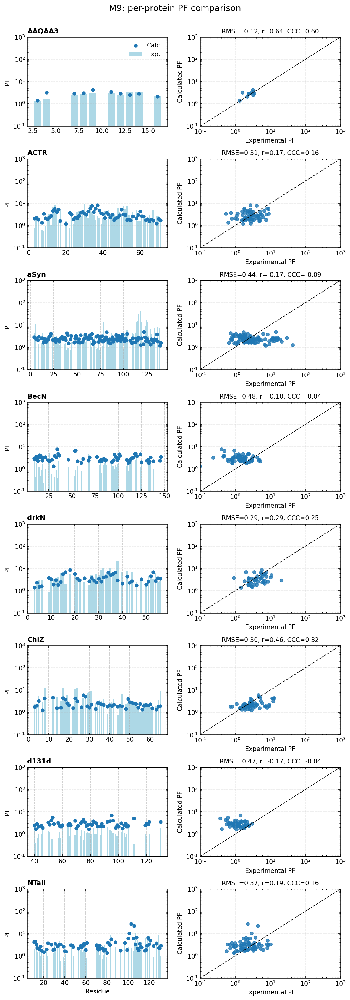

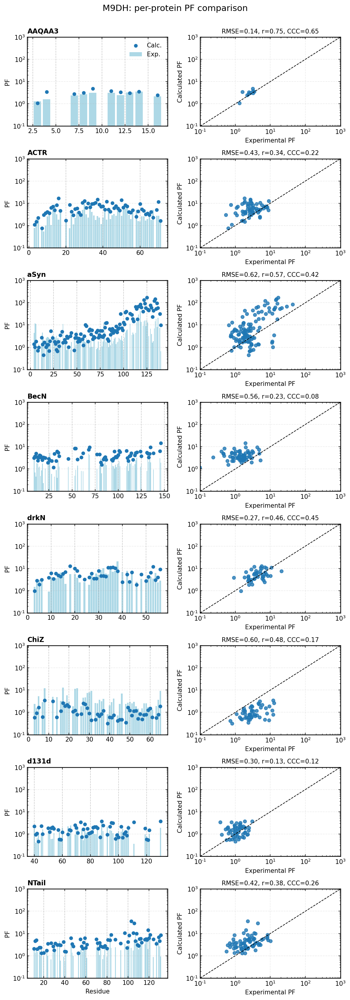

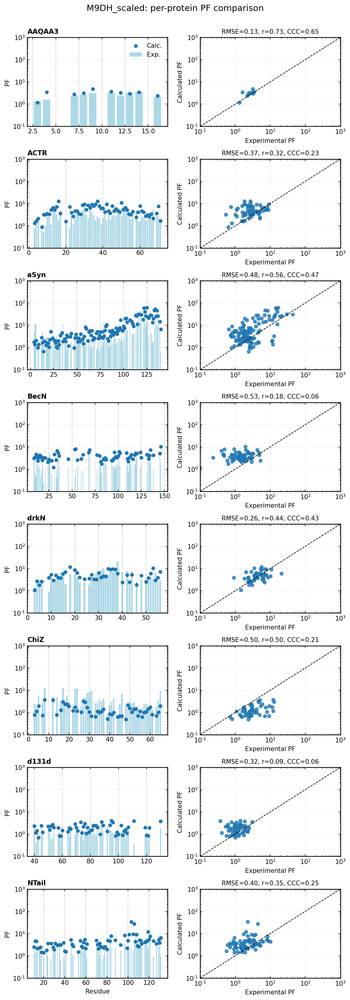

...

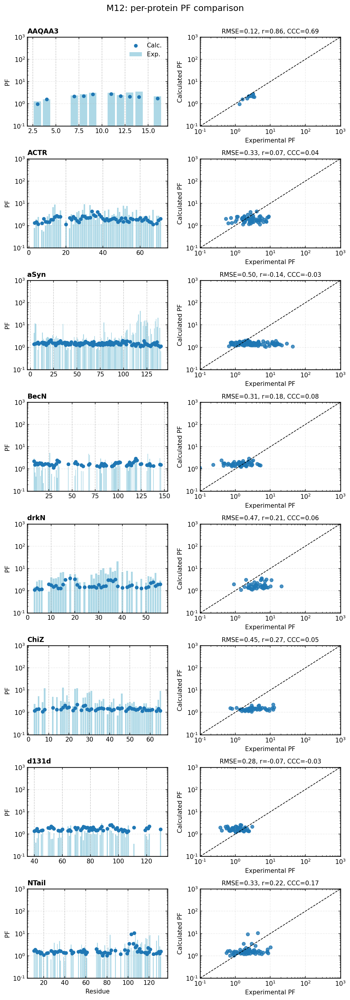

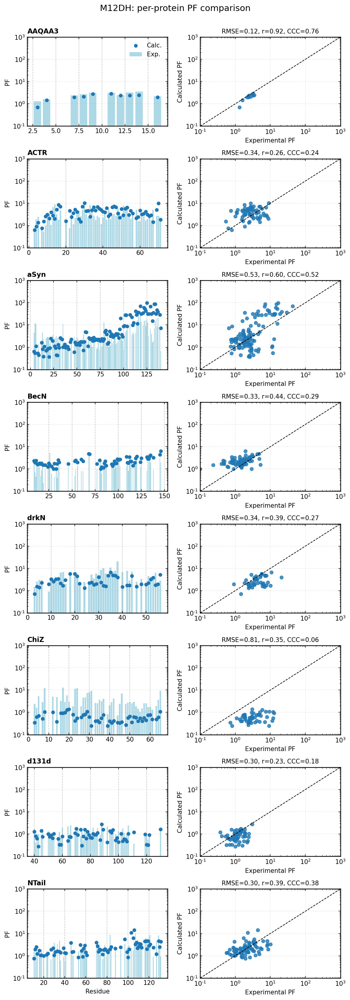

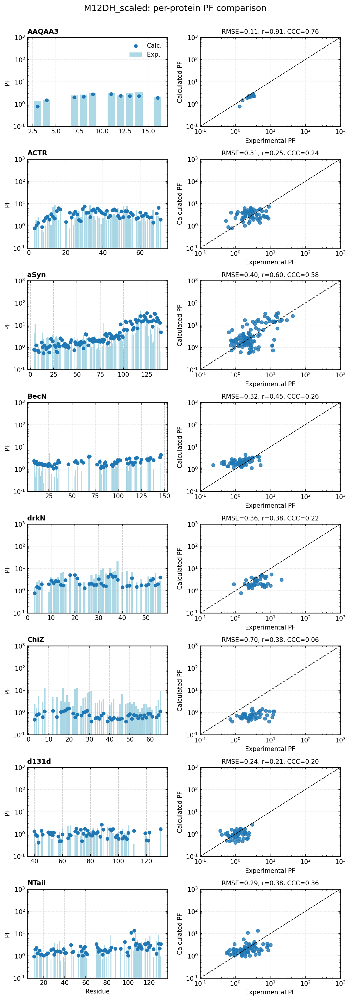

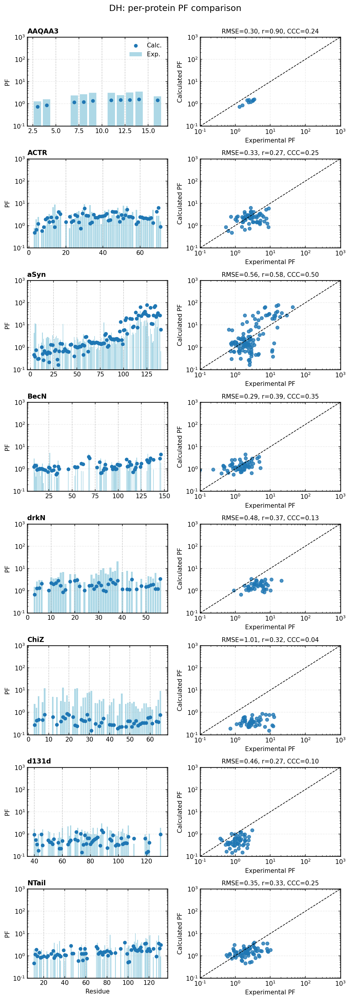

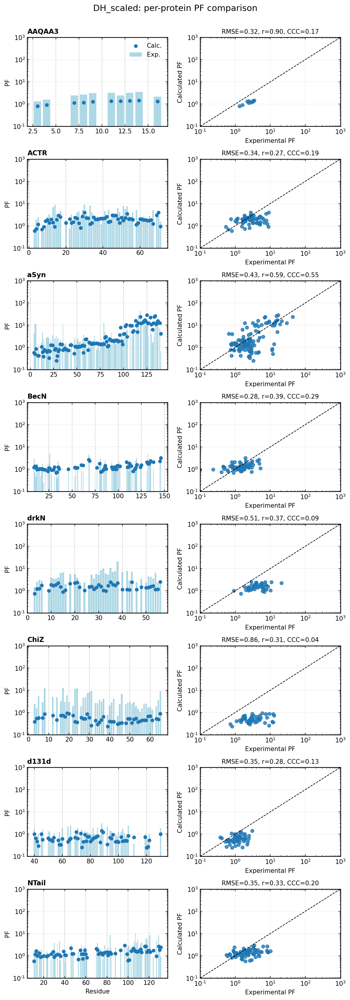

In [4]:
# per-protein plots

for model_i, model in enumerate(models):

    nrows = len(proteins)

    fig, axes = plt.subplots(
        nrows, 2,
        figsize=(8, 2.8 * nrows),
        squeeze=False
    )

    for i, protein in enumerate(proteins):

        ax_pf = axes[i, 0]
        ax_corr = axes[i, 1]

        df_model = pd.read_csv(f"{model}_PF_perres_comparison.csv")
        dfp = df_model[df_model["Protein"] == protein].copy()

        exp_res = dfp["Residue"].values
        PF_exp = dfp["PF_Exp"].values
        PF_sim = dfp["PF_Sim"].values

        logPF_exp = np.log10(PF_exp)
        logPF_sim = np.log10(PF_sim)

        rmse_val = RMSE(logPF_exp, logPF_sim)
        r_val = scipy.stats.pearsonr(logPF_exp, logPF_sim)[0]
        ccc_val = ccc(logPF_exp, logPF_sim)

        # -------------------------
        # left column: residue vs PF
        # -------------------------
        ax_pf.bar(
            exp_res,
            PF_exp,
            width=0.8,
            color="lightblue",
            edgecolor="none",
            label="Exp."
        )

        ax_pf.scatter(
            exp_res,
            PF_sim,
            s=25,
            color="tab:blue",
            zorder=3,
            label="Calc."
        )

        ax_pf.set_yscale("log")
        ax_pf.set_ylabel("PF")
        ax_pf.set_ylim(1e-1, 1e3)
        ax_pf.set_title(protein, loc="left", fontsize=11, fontweight="bold")
        ax_pf.grid(alpha=0.25, axis="y")

        if i == nrows - 1:
            ax_pf.set_xlabel("Residue")

        if i == 0:
            ax_pf.legend(frameon=False)

        # -------------------------
        # right column: correlation plot
        # -------------------------
        ax_corr.scatter(
            PF_exp,
            PF_sim,
            s=28,
            color="tab:blue",
            alpha=0.8
        )

        xmin = min(np.min(PF_exp), np.min(PF_sim))
        xmax = max(np.max(PF_exp), np.max(PF_sim))

        ax_corr.plot(
            [1e-1, 1e3],
            [1e-1, 1e3],
            "k--",
            lw=1
        )

        ax_corr.set_xscale("log")
        ax_corr.set_yscale("log")
        ax_corr.set_xlim(1e-1, 1e3)
        ax_corr.set_ylim(1e-1, 1e3)

        ax_corr.set_xlabel("Experimental PF")
        ax_corr.set_ylabel("Calculated PF")
        ax_corr.grid(alpha=0.25)

        ax_corr.set_title(
            f"RMSE={rmse_val:.2f}, r={r_val:.2f}, CCC={ccc_val:.2f}",
            fontsize=10
        )

    fig.suptitle(f"{model}: per-protein PF comparison", fontsize=14, y=1.002)

    plt.tight_layout()
    plt.savefig(
        f"{model}_PF_perprotein_panels.png",
        dpi=200,
        bbox_inches="tight"
    )
    plt.show()

Total unique proteins: 8


/tmp/ipykernel_1941938/228636479.py:43: DeprecationWarning: loadtxt(): Parsing an integer via a float is deprecated.  To avoid this warning, you can:
    * make sure the original data is stored as integers.
    * use the `converters=` keyword argument.  If you only use
      NumPy 1.23 or later, `converters=float` will normally work.
    * Use `np.loadtxt(...).astype(np.int64)` parsing the file as
      floating point and then convert it.  (On all NumPy versions.)
  (Deprecated NumPy 1.23)
  amide_residues = np.loadtxt(f"../../MD_DATA/{protein}/rew{model}/amideresidues.txt", dtype=int)
/tmp/ipykernel_1941938/228636479.py:43: DeprecationWarning: loadtxt(): Parsing an integer via a float is deprecated.  To avoid this warning, you can:
    * make sure the original data is stored as integers.
    * use the `converters=` keyword argument.  If you only use
      NumPy 1.23 or later, `converters=float` will normally work.
    * Use `np.loadtxt(...).astype(np.int64)` parsing the file as
      

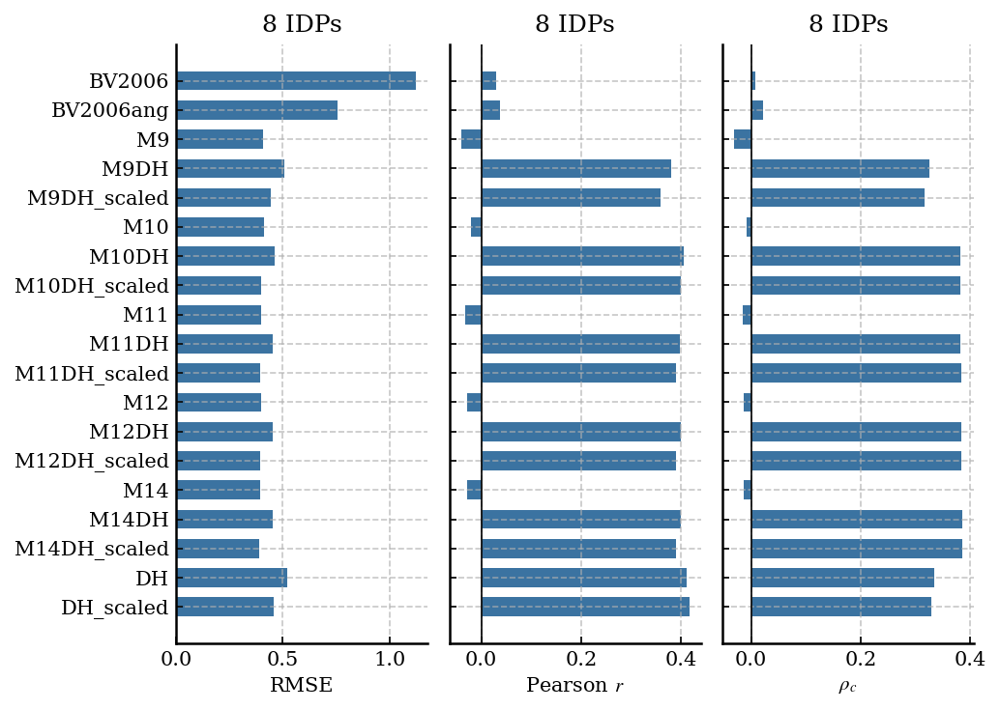

In [9]:

# only integrative IDPs
# prior weights (no NMR/SAXS reweighting)

models = ['BV2006', 'BV2006ang', 'M9', 'M9DH', 'M9DH_scaled', 'M10', 'M10DH', 'M10DH_scaled',
          'M11', 'M11DH', 'M11DH_scaled', 'M12', 'M12DH', 'M12DH_scaled',
          'M14', 'M14DH', 'M14DH_scaled', 'DH', 'DH_scaled']

proteins = ['AAQAA3', 'ACTR', 'aSyn', 'BecN', 'drkN', 'ChiZ', 'd131d', 'NTail']

print("Total unique proteins:", len(proteins))

COLOR = "#3B73A1"

rmse_all = []
r_all = []
ccc_all = []
all_exp_PF = []
all_sim_PF = []

for model in models:

    exp_PF_vals = []
    sim_PF_vals = []
    residues_vals = []
    protein_vals = []

    for protein in proteins:

        # load experimental data
        exp_data = pd.read_csv(f"../../EXP_DATA/PF_Nguyen_2018/{protein}.csv")
        exp_res = exp_data['Model_residue'].values
        PF_exp = exp_data['PF'].values

        # no integrative weights
        weights = None

        # load simulated data
        if 'BV' in model:
            sim_data1 = np.load(f"../../MD_DATA/{protein}/rew{model}/contacts_res_frames.npy")
            sim_data2 = np.load(f"../../MD_DATA/{protein}/rew{model}/hbonds_res_frames.npy")
            sim_data = model_params[model]['beta_c'] * sim_data1 + model_params[model]['beta_h'] * sim_data2
            PF_sim = np.exp(np.average(sim_data, axis=0, weights=weights))
            amide_residues = np.loadtxt(f"../../MD_DATA/{protein}/rew{model}/amideresidues.txt", dtype=int)
        else:
            fopen = None
            for fname in ["fopen.npy", "fopenDH.npy", "O.npy"]:
                path = f"../../MD_DATA/{protein}/rew{model}/{fname}"
                try:
                    fopen = np.load(path)
                    break
                except FileNotFoundError:
                    continue

            if fopen is None:
                raise FileNotFoundError(f"No fopen.npy, fopenDH.npy or O.npy found for {protein}, {model}")

            amide_residues = np.loadtxt(f"../../MD_DATA/{protein}/rewM10/amideresidues.txt", dtype=int)
            PF_sim = 1 / np.average(fopen, axis=0, weights=weights)

        # align simulated and experimental data
        matched_exp_idxs = []
        matched_sim_idxs = []

        for exp_idx, res in enumerate(exp_res):
            if res in amide_residues:
                matched_exp_idxs.append(exp_idx)
                matched_sim_idxs.append(np.where(amide_residues == res)[0][0])

        matched_exp_idxs = np.asarray(matched_exp_idxs, dtype=int)
        matched_sim_idxs = np.asarray(matched_sim_idxs, dtype=int)

        PF_exp_matched = PF_exp[matched_exp_idxs]
        PF_sim_matched = PF_sim[matched_sim_idxs]
        exp_res_matched = exp_res[matched_exp_idxs]

        valid = np.isfinite(PF_exp_matched) & np.isfinite(PF_sim_matched) & (PF_exp_matched > 0) & (PF_sim_matched > 0)

        PF_exp_matched = PF_exp_matched[valid]
        PF_sim_matched = PF_sim_matched[valid]
        exp_res_matched = exp_res_matched[valid]

        exp_PF_vals.extend(PF_exp_matched)
        sim_PF_vals.extend(PF_sim_matched)
        residues_vals.extend(exp_res_matched)
        protein_vals.extend(np.repeat(protein, len(PF_exp_matched)))

    exp_PF_vals = np.asarray(exp_PF_vals)
    sim_PF_vals = np.asarray(sim_PF_vals)

    log_exp = np.log10(exp_PF_vals)
    log_sim = np.log10(sim_PF_vals)

    # calculate statistics using all pooled residues
    rmse_all.append(RMSE(log_exp, log_sim))
    r_all.append(scipy.stats.pearsonr(log_exp, log_sim)[0])
    ccc_all.append(calc_ccc(log_exp, log_sim))

    all_exp_PF.append(exp_PF_vals)
    all_sim_PF.append(sim_PF_vals)

    # save dataframe for this model
    df = pd.DataFrame({'Protein': protein_vals, 'Residue': residues_vals, 'PF_Exp': exp_PF_vals, 'PF_Sim': sim_PF_vals})
    df.to_csv(f"{model}_PF_perres_comparison_uniform_weights.csv", index=False)

# ---- Plot ----
fig, axes = plt.subplots(1, 3, figsize=(7, 5), sharey=True)

y = np.arange(len(models))

for ax, values, xlabel in zip(axes, [rmse_all, r_all, ccc_all], ['RMSE', 'Pearson $r$', r'$\mathit{\rho_c}$']):
    ax.barh(y, values, height=0.65, color=COLOR)
    ax.set_xlabel(xlabel)
    ax.axvline(0, color='black', linewidth=0.8)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(axis='both', which='both', top=False, right=False)

axes[0].set_yticks(y)
axes[0].set_yticklabels(models)
axes[0].invert_yaxis()

axes[0].set_title(f"{len(proteins)} IDPs")
axes[1].set_title(f"{len(proteins)} IDPs")
axes[2].set_title(f"{len(proteins)} IDPs")

plt.tight_layout()
plt.savefig('models_HDXstats_summary_uniform_weights.pdf', dpi=300)
plt.show()

